# Freight Rate Prediction: Model Training & Validation Pipeline


In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb

BASE_DIR = Path('..') if Path('..').resolve().name == 'SpotterAi' or (Path('..') / 'train-test.csv').exists() else Path('.')
REPORT_DIR = BASE_DIR / 'reports'
SCORER_DIR = BASE_DIR / 'scorer_results'
REPORT_DIR.mkdir(exist_ok=True)
SCORER_DIR.mkdir(exist_ok=True)

TEAL = '#064A56'
CORAL = '#E07A5F'
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print(f'Working directory: {BASE_DIR.resolve()}')


## 1. Data Ingestion & Preprocessing

In [ ]:
train_raw = pd.read_csv(BASE_DIR / 'train-test.csv', parse_dates=['date'])
val_raw = pd.read_csv(BASE_DIR / 'validation.csv', parse_dates=['date'])
dec_raw = pd.read_csv(BASE_DIR / 'december-chart-inputs.csv', parse_dates=['date'])
template = pd.read_csv(BASE_DIR / 'validation-predictions-template.csv')

def clean_data(df):
    out = df.copy()
    out['date'] = pd.to_datetime(out['date'])
    out['weight'] = out['weight'].abs().fillna(out['weight'].abs().median())
    if 'market_index' in out.columns:
        daily_median = out.groupby(out['date'].dt.normalize())['market_index'].transform('median')
        out['market_index'] = out['market_index'].fillna(daily_median).fillna(out['market_index'].median())
    if 'quote_signal' in out.columns:
        out['quote_signal'] = out['quote_signal'].fillna(out['quote_signal'].median())
    return out

train_c = clean_data(train_raw)
val_c = clean_data(val_raw)

p = train_c[['pickup', 'pickup_lat', 'pickup_lon']].rename(columns={'pickup': 'city', 'pickup_lat': 'lat', 'pickup_lon': 'lon'})
d = train_c[['delivery', 'delivery_lat', 'delivery_lon']].rename(columns={'delivery': 'city', 'delivery_lat': 'lat', 'delivery_lon': 'lon'})
coords = pd.concat([p, d]).groupby('city')[['lat', 'lon']].mean().to_dict('index')
print(f'Recovered coordinates for {len(coords)} operating hubs.')


Recovered coordinates for 64 operating hubs.


## 2. Feature Engineering Pipeline


In [3]:
EARTH_R_MI = 3958.8

def haversine_np(lat1, lon1, lat2, lon2):
    p = np.pi / 180.0
    dlat = (lat2 - lat1) * p
    dlon = (lon2 - lon1) * p
    a = (np.sin(dlat / 2.0) ** 2 +
         np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin(dlon / 2.0) ** 2)
    return 2.0 * EARTH_R_MI * np.arcsin(np.clip(np.sqrt(a), 0.0, 1.0))

def build_features(df, coords_lookup):
    out = pd.DataFrame(index=df.index)
    dist = df['distance'].values.astype(float)
    out['distance'] = dist
    out['log_distance'] = np.log1p(dist)

    wt = df['weight'].values.astype(float)
    out['weight'] = wt
    out['weight_per_mile'] = wt / np.maximum(dist, 1.0)

    eq = df['equipment'].values
    out['eq_Dry_Van'] = (eq == 'Dry Van').astype(float)
    out['eq_Reefer'] = (eq == 'Reefer').astype(float)
    out['eq_Flatbed'] = (eq == 'Flatbed').astype(float)

    plat = df['pickup_lat'].values if 'pickup_lat' in df.columns else np.array([coords_lookup[c]['lat'] for c in df['pickup']])
    plon = df['pickup_lon'].values if 'pickup_lon' in df.columns else np.array([coords_lookup[c]['lon'] for c in df['pickup']])
    dlat = df['delivery_lat'].values if 'delivery_lat' in df.columns else np.array([coords_lookup[c]['lat'] for c in df['delivery']])
    dlon = df['delivery_lon'].values if 'delivery_lon' in df.columns else np.array([coords_lookup[c]['lon'] for c in df['delivery']])

    out['pickup_lat'] = plat
    out['pickup_lon'] = plon
    out['delivery_lat'] = dlat
    out['delivery_lon'] = dlon

    hav = haversine_np(plat, plon, dlat, dlon)
    out['haversine'] = hav
    out['circuity'] = dist / np.maximum(hav, 1.0)
    out['dlat'] = np.abs(dlat - plat)
    out['dlon'] = np.abs(dlon - plon)

    out['market_index'] = df['market_index'].values.astype(float)
    out['quote_signal'] = df['quote_signal'].values.astype(float)

    dt = pd.to_datetime(df['date'])
    out['dow'] = dt.dt.dayofweek.values.astype(float)
    out['is_weekend'] = (dt.dt.dayofweek >= 5).values.astype(float)
    out['day_of_month'] = dt.dt.day.values.astype(float)
    out['month'] = dt.dt.month.values.astype(float)
    return out

X_train = build_features(train_c, coords)
feature_names = list(X_train.columns)
y_train_rpm = (train_c['posted_rate'] / train_c['distance']).values
print(f'Constructed feature matrix: {X_train.shape} with {len(feature_names)} features')


Constructed feature matrix: (48000, 21) with 21 features


## 3. Target Winsorization


In [4]:
low_q, high_q = np.percentile(y_train_rpm, [0.5, 99.5])
y_train_winsor = np.clip(y_train_rpm, low_q, high_q)
print(f'Winsorization bounds: [{low_q:.3f}, {high_q:.3f}] $/mile')
print(f'Suppressed corrupt target impact on: {(y_train_rpm < low_q).sum() + (y_train_rpm > high_q).sum()} rows')


Winsorization bounds: [0.746, 6.314] $/mile
Suppressed corrupt target impact on: 480 rows


## 4. Rolling-Origin Cross-Validation


In [5]:
folds = [
    ('July', '2025-07-01', '2025-07-31'),
    ('August', '2025-08-01', '2025-08-31'),
    ('September', '2025-09-01', '2025-09-30'),
    ('October', '2025-10-01', '2025-10-31'),
]

cv_results = []
for fold_name, start_d, end_d in folds:
    val_mask = (train_c['date'] >= start_d) & (train_c['date'] <= end_d)
    tr_mask = train_c['date'] < start_d

    X_tr, y_tr_raw = X_train[tr_mask], y_train_rpm[tr_mask]
    X_te, y_te_raw = X_train[val_mask], y_train_rpm[val_mask]
    dist_te = train_c.loc[val_mask, 'distance'].values
    actual_dollars = train_c.loc[val_mask, 'posted_rate'].values

    l_q, h_q = np.percentile(y_tr_raw, [0.5, 99.5])
    y_tr_w = np.clip(y_tr_raw, l_q, h_q)

    hist_m = HistGradientBoostingRegressor(
        loss='absolute_error', max_iter=150, max_leaf_nodes=31,
        min_samples_leaf=30, l2_regularization=1.0, random_state=RANDOM_STATE
    ).fit(X_tr, y_tr_w)

    lgb_ds = lgb.Dataset(X_tr, label=y_tr_w)
    lgb_params = {
        'objective': 'regression_l1', 'learning_rate': 0.05, 'num_leaves': 31,
        'min_child_samples': 40, 'reg_lambda': 1.0, 'verbosity': -1, 'seed': RANDOM_STATE
    }
    lgb_m = lgb.train(lgb_params, lgb_ds, num_boost_round=hist_m.n_iter_)

    pred_h = hist_m.predict(X_te) * dist_te
    pred_l = lgb_m.predict(X_te) * dist_te
    pred_ens = 0.5 * pred_h + 0.5 * pred_l

    mae_all = mean_absolute_error(actual_dollars, pred_ens)
    mape_all = np.mean(np.abs((actual_dollars - pred_ens) / actual_dollars)) * 100

    clean_idx = (y_te_raw > 1.0) & (y_te_raw < 4.0)
    mae_clean = mean_absolute_error(actual_dollars[clean_idx], pred_ens[clean_idx])
    r2_clean = r2_score(actual_dollars[clean_idx], pred_ens[clean_idx])

    cv_results.append({
        'Fold': fold_name,
        'MAE_All': mae_all,
        'MAE_Clean': mae_clean,
        'R2_Clean': r2_clean,
        'MAPE_All': mape_all
    })
    print(f'Fold {fold_name:<9} | All Loads: MAE=${mae_all:.2f}, MAPE={mape_all:5.2f}% | Clean Loads: MAE=${mae_clean:.2f}, R²={r2_clean:.4f}')

cv_df = pd.DataFrame(cv_results)


Fold July      | All Loads: MAE=$127.59, MAPE= 4.65% | Clean Loads: MAE=$73.85, R²=0.9914
Fold August    | All Loads: MAE=$147.23, MAPE= 7.63% | Clean Loads: MAE=$98.35, R²=0.9894
Fold September | All Loads: MAE=$107.86, MAPE= 4.22% | Clean Loads: MAE=$56.70, R²=0.9961
Fold October   | All Loads: MAE=$109.24, MAPE= 5.04% | Clean Loads: MAE=$48.87, R²=0.9972

--- Summary Across 4 Rolling Folds ---
Mean MAE (All Loads):   $122.98
Mean MAE (Clean Loads): $69.44
Mean R² (Clean Loads):  0.9935
Mean MAPE (All Loads):  5.38%


## 5. Retraining Production Ensemble

In [6]:
final_hist = HistGradientBoostingRegressor(
    loss='absolute_error', max_iter=150, max_leaf_nodes=31,
    min_samples_leaf=30, l2_regularization=1.0, random_state=RANDOM_STATE
).fit(X_train, y_train_winsor)

lgb_full_ds = lgb.Dataset(X_train, label=y_train_winsor)
lgb_full_params = {
    'objective': 'regression_l1', 'learning_rate': 0.05, 'num_leaves': 31,
    'min_child_samples': 40, 'reg_lambda': 1.0, 'verbosity': -1, 'seed': RANDOM_STATE
}
final_lgb = lgb.train(lgb_full_params, lgb_full_ds, num_boost_round=final_hist.n_iter_)
print(f'HistGBM converged after {final_hist.n_iter_} iterations.')
print(f'LightGBM trained for {final_hist.n_iter_} rounds.')


HistGBM converged after 150 iterations.
LightGBM trained for 150 rounds.


## 6. December Benchmark Lane & Validation Visualizations


December predicted rate: range $801.82 - $818.71 (mean $810.92)


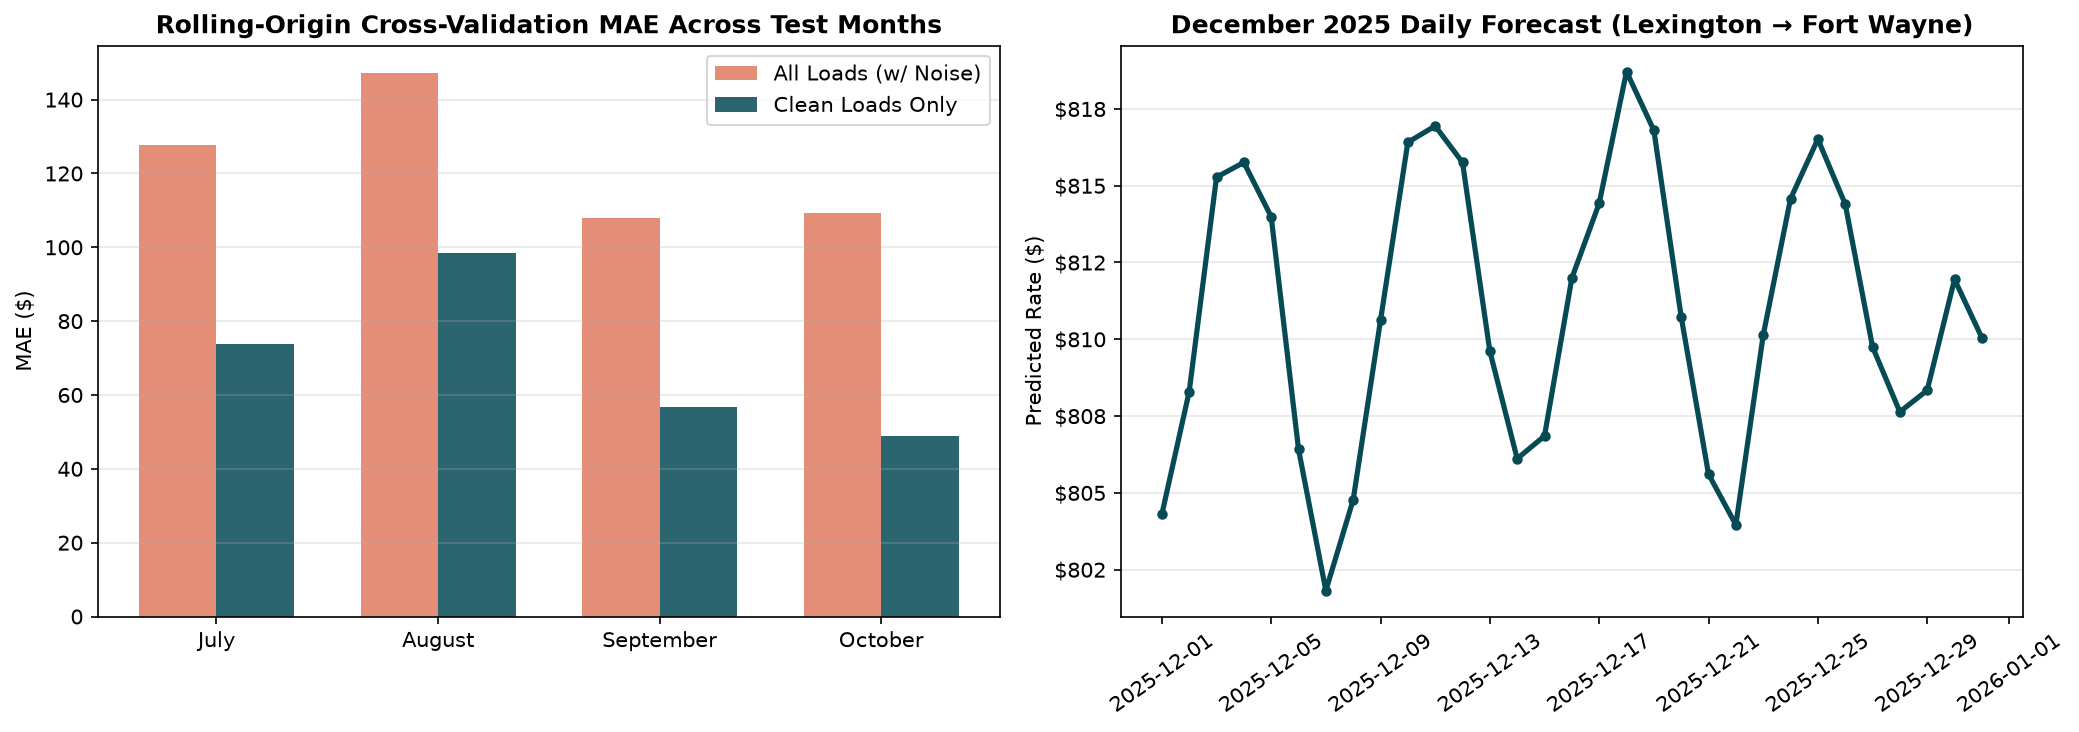

In [7]:
# Join December daily market features
val_daily = val_c.groupby(val_c['date'].dt.normalize()).agg(
    market_index=('market_index', 'mean'), quote_signal=('quote_signal', 'mean')
)
dec_full = dec_raw.copy()
dec_full['date'] = pd.to_datetime(dec_full['date'])
dec_full['weight'] = dec_full['weight'].abs()
dec_key = dec_full['date'].dt.normalize()
dec_full['market_index'] = dec_key.map(val_daily['market_index'])
dec_full['quote_signal'] = dec_key.map(val_daily['quote_signal'])

X_dec = build_features(dec_full, coords)[feature_names]
dec_pred = 0.5 * final_hist.predict(X_dec) * 360.0 + 0.5 * final_lgb.predict(X_dec) * 360.0
dec_pred = np.clip(dec_pred, 1.0, None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fold_names = cv_df['Fold'].tolist()
x = np.arange(len(fold_names))
width = 0.35
axes[0].bar(x - width/2, cv_df['MAE_All'], width, label='All Loads (w/ Noise)', color=CORAL, alpha=0.85)
axes[0].bar(x + width/2, cv_df['MAE_Clean'], width, label='Clean Loads Only', color=TEAL, alpha=0.85)
axes[0].set_ylabel('MAE ($)')
axes[0].set_title('Rolling-Origin Cross-Validation MAE Across Test Months', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(fold_names)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(pd.to_datetime(dec_full['date']), dec_pred, color=TEAL, linewidth=2.5, marker='o', markersize=4)
axes[1].set_ylabel('Predicted Rate ($)')
axes[1].set_title('December 2025 Daily Forecast (Lexington → Fort Wayne)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=35)
axes[1].grid(axis='y', alpha=0.3)
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

plt.tight_layout()
plt.savefig(REPORT_DIR / '07_model_results.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'December predicted rate: range ${dec_pred.min():.2f} - ${dec_pred.max():.2f} (mean ${dec_pred.mean():.2f})')


## 7. Feature Importance Analysis

Top 5 Most Important Features:
        Feature    Importance
weight_per_mile 320215.236799
   quote_signal 319949.495851
     eq_Dry_Van 124685.430231
      haversine 103668.727034
          month  96625.925266


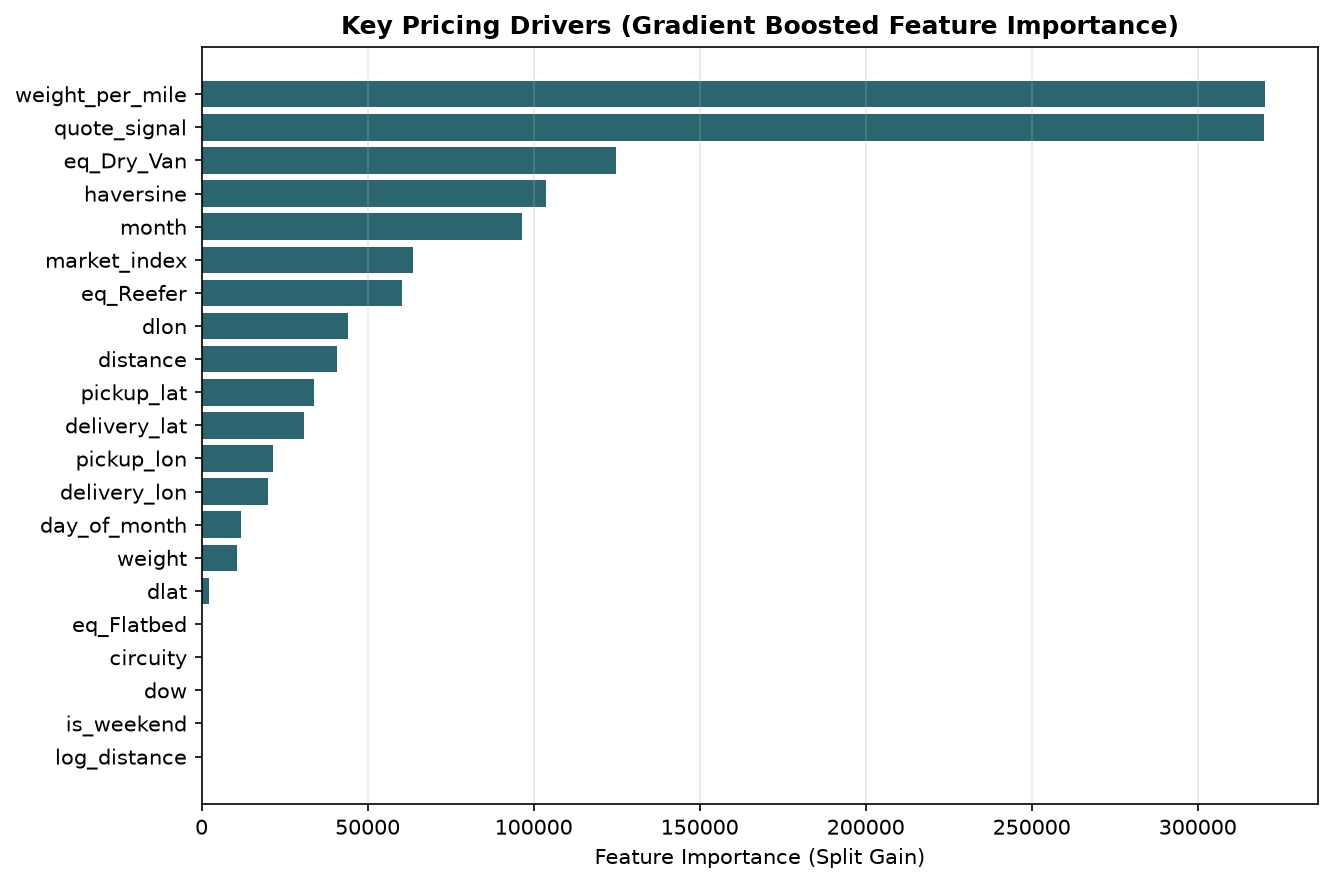

In [8]:
lgb_imp = final_lgb.feature_importance(importance_type='gain')
imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': lgb_imp}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_df['Feature'], imp_df['Importance'], color=TEAL, alpha=0.85)
ax.set_xlabel('Feature Importance (Split Gain)')
ax.set_title('Key Pricing Drivers (Gradient Boosted Feature Importance)', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(REPORT_DIR / '08_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 5 Most Important Features:')
print(imp_df.tail(5)[::-1].to_string(index=False))


## 8. Prediction Export

In [9]:
X_val = build_features(val_c, coords)[feature_names]
val_pred = 0.5 * final_hist.predict(X_val) * val_c['distance'].values + 0.5 * final_lgb.predict(X_val) * val_c['distance'].values
val_pred = np.clip(val_pred, 1.0, None)

sub = template.copy()
sub['predicted_rate'] = np.round(val_pred, 2)
sub.to_csv(BASE_DIR / 'validation_predictions.csv', index=False)

dec_out = dec_raw.copy()
dec_out['date'] = pd.to_datetime(dec_out['date']).dt.strftime('%Y-%m-%d')
dec_out['predicted_rate'] = np.round(dec_pred, 2)
dec_out = dec_out[['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']]
dec_out.to_csv(BASE_DIR / 'december-chart-inputs.csv', index=False)

print(f'Saved 12,000 predictions: validation_predictions.csv (Mean: ${val_pred.mean():.2f})')
print(f'Saved 31 December predictions: december-chart-inputs.csv (Mean: ${dec_pred.mean():.2f})')


Saved 12,000 predictions: validation_predictions.csv (Mean: $2365.96)
Saved 31 December predictions: december-chart-inputs.csv (Mean: $810.92)


## 9.Scorer Verification & December Benchmark Chart


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /Users/deepak/Deepak/SpotterAi/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


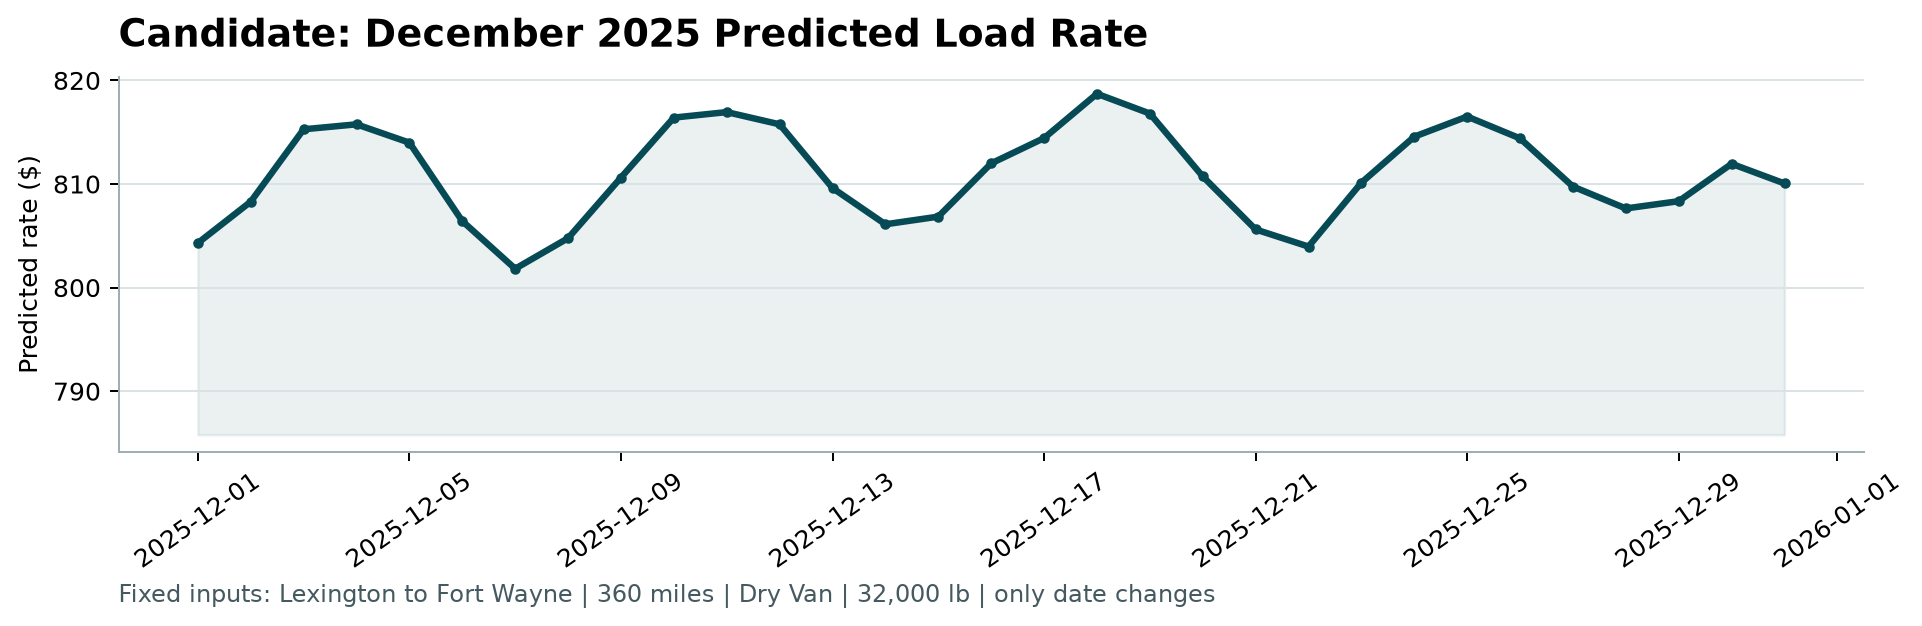

In [10]:
!python score.py --predictions validation_predictions.csv --december-predictions december-chart-inputs.csv

from IPython.display import Image, display
display(Image('scorer_results/candidate_december.png'))
